In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB

In [2]:
df = pd.read_csv("admission_data.csv")

75th percentile cutoff: 0.82
Admit
No     376
Yes    124
Name: count, dtype: int64


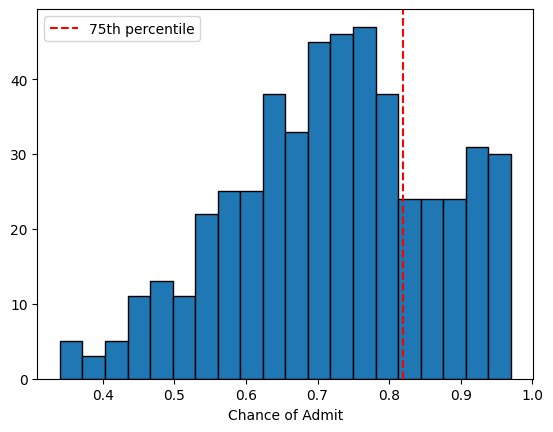

In [3]:
df.columns = df.columns.str.strip()
df = df.dropna()

cutoff = df["Chance of Admit"].quantile(0.75)
df["Admit"] = np.where(df["Chance of Admit"] > cutoff, "Yes", "No")

print("75th percentile cutoff:", cutoff)
print(df["Admit"].value_counts())

plt.hist(df["Chance of Admit"], bins=20, edgecolor="black")
plt.axvline(cutoff, color="red", linestyle="--", label="75th percentile")
plt.xlabel("Chance of Admit")
plt.legend()
plt.show()

In [4]:
X = df.drop(columns=["Chance of Admit", "Admit"])
y = df["Admit"]
print("X shape:", X.shape)

X shape: (500, 7)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (400, 7)  Test: (100, 7)


In [6]:
def evaluate(name, model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=model.classes_).plot()
    plt.title("Confusion Matrix - " + name)
    plt.show()

    result = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, average="weighted", zero_division=0),
    }
    print("=====", name, "=====")
    for metric, value in list(result.items())[1:]:
        print(f"{metric:10s}: {value:.4f}")
    return result

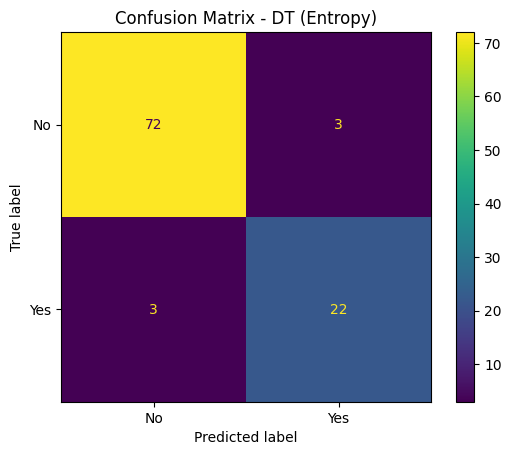

===== DT (Entropy) =====
Accuracy  : 0.9400
Precision : 0.9400
Recall    : 0.9400
F1-Score  : 0.9400


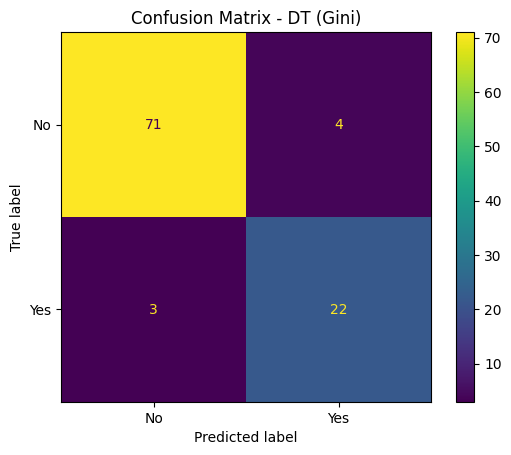

===== DT (Gini) =====
Accuracy  : 0.9300
Precision : 0.9311
Recall    : 0.9300
F1-Score  : 0.9305


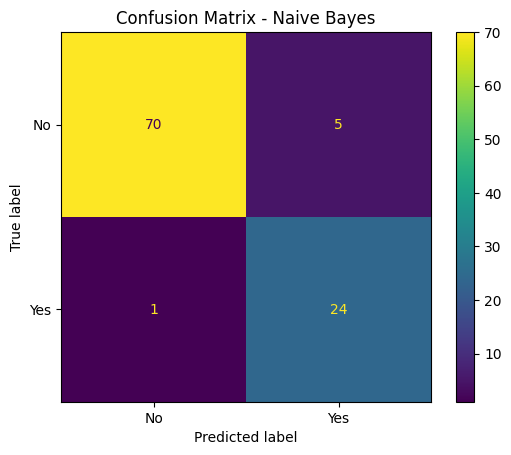

===== Naive Bayes =====
Accuracy  : 0.9400
Precision : 0.9463
Recall    : 0.9400
F1-Score  : 0.9414


In [7]:
models = {
    "DT (Entropy)": DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=42),
    "DT (Gini)": DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=42),
    "Naive Bayes": GaussianNB(),
}

results = []
for name, model in models.items():
    results.append(evaluate(name, model, X_train, X_test, y_train, y_test))

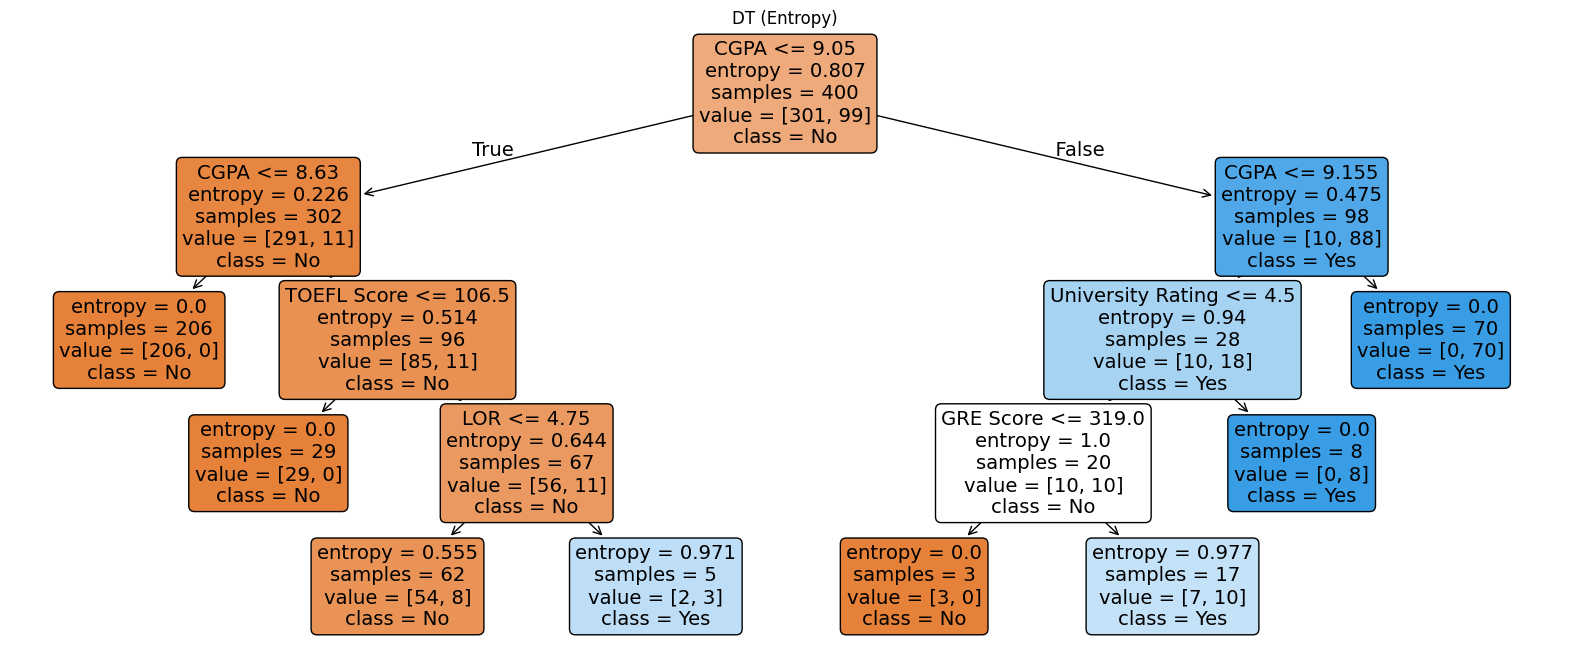

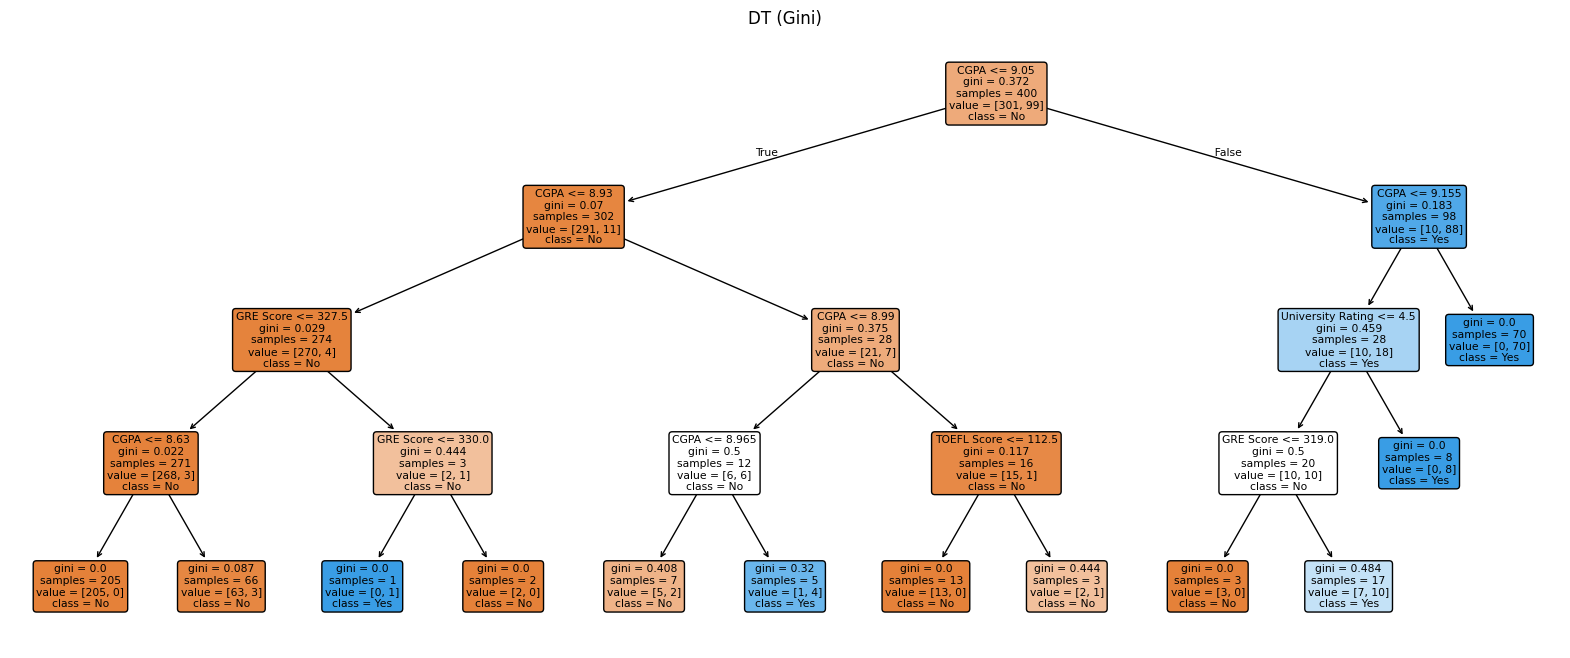

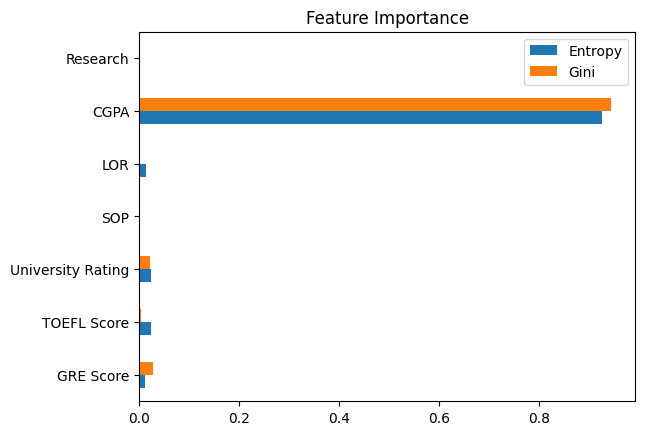

In [8]:
for name in ["DT (Entropy)", "DT (Gini)"]:
    plt.figure(figsize=(20, 8))
    plot_tree(models[name], feature_names=X.columns, class_names=models[name].classes_, filled=True, rounded=True)
    plt.title(name)
    plt.show()

importance = pd.DataFrame({
    "Entropy": models["DT (Entropy)"].feature_importances_,
    "Gini": models["DT (Gini)"].feature_importances_,
}, index=X.columns)

importance.plot(kind="barh")
plt.title("Feature Importance")
plt.show()

In [ ]:
print("Prior probabilities:")
print(y_train.value_counts(normalize=True).round(3))

X_cat = X_train.copy()
for col in X_cat.columns:
    if X_cat[col].nunique() > 5:
        X_cat[col] = pd.qcut(X_cat[col], 3, labels=["Low", "Medium", "High"])

likelihood = pd.concat(
    [pd.crosstab(X_cat[col], y_train, normalize="columns") for col in X_cat.columns],
    keys=X_cat.columns, names=["Feature", "Value"]
)
likelihood.columns = ["P(x | No)", "P(x | Yes)"]
likelihood.round(3)

Prior probabilities:
Admit
No     0.752
Yes    0.248
Name: proportion, dtype: float64


P(x | No)  P(x | Yes)
Feature           Value                        
GRE Score         Low         0.488       0.000
                  Medium      0.352       0.162
                  High        0.159       0.838
TOEFL Score       Low         0.462       0.000
                  Medium      0.415       0.131
                  High        0.123       0.869
University Rating 1           0.090       0.000
                  2           0.329       0.020
                  3           0.405       0.101
                  4           0.143       0.374
                  5           0.033       0.505
SOP               Low         0.555       0.040
                  Medium      0.379       0.343
                  High        0.066       0.616
LOR               Low         0.528       0.081
                  Medium      0.362       0.354
                  High        0.110       0.566
CGPA              Low         0.449       0.000
                  Medium      0.429       0.040
                  High        0.123       0.960
Research          0           0.575       0.051
                  1           0.425       0.949

              Accuracy  Precision  Recall  F1-Score
Model                                              
DT (Entropy)      0.94     0.9400    0.94    0.9400
DT (Gini)         0.93     0.9311    0.93    0.9305
Naive Bayes       0.94     0.9463    0.94    0.9414


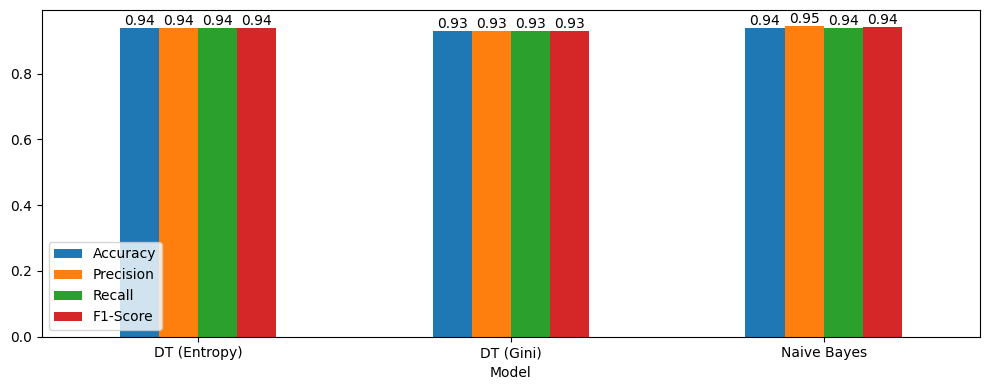

In [19]:
results_df = pd.DataFrame(results).set_index("Model")
print(results_df.round(4))

ax = results_df.plot(kind="bar", figsize=(10, 4), rot=0, legend=True)
for bars in ax.containers:
    plt.bar_label(bars, fmt="%.2f")
plt.tight_layout()
plt.show()

In [ ]:
# predict from user input (press Enter to use the average value)

user = {}
for col in X.columns:
    val = input(f"{col} [{X[col].mean():.2f}]: ").strip()
    user[col] = float(val) if val else X[col].mean()
user_df = pd.DataFrame([user])

print("\nInput:", user)
for name, model in models.items():
    pred = model.predict(user_df)[0]
    p_yes = model.predict_proba(user_df)[0][list(model.classes_).index("Yes")]
    print(f"{name:13s} -> Admit: {pred}  (P(Yes) = {p_yes:.2f})")